In [4]:
import h5py

snap = h5py.File("./DIIID_resources/snapshots.h5")

In [5]:
print(list(snap.keys()))

['grid_ni', 'grid_phi', 'iteration']


In [11]:
density = snap["grid_ni"][:]
phi = snap["grid_phi"][:]
iter = snap["iteration"][:]

In [12]:
print(density.shape)
print(phi.shape)
print(iter.shape)

(4695, 4)
(4695, 4)
(1, 4)


In [21]:
print(iter)
print(phi[0])
print(density[0])

[[  1   1   2 100]]
[ 1.  0. -0.  0.]
[ 1.  0.  0. -0.]


In [20]:
print(phi[64])
print(density[64])

[ 1.  0.  0. -0.]
[1. 0. 0. 0.]


In [22]:
print(phi[2000])
print(density[2000])

[ 1.0000000e+00  0.0000000e+00 -1.4426828e-11 -1.7081842e-12]
[ 1.0000000e+00  0.0000000e+00 -1.7137740e-05 -1.0161395e-05]


In [23]:
print(phi[4000])
print(density[4000])

[1.0000000e+00 0.0000000e+00 4.4255797e-12 1.3045585e-12]
[ 1.0000000e+00  0.0000000e+00  1.4222808e-05 -7.1976128e-06]


In [24]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [25]:
X_train_np = density[:, :3].T.reshape(-1, 1)
y_train_np = phi[:, :3].T.reshape(-1, 1)

X_test_np = density[:, 3].reshape(-1, 1)
y_test_np = phi[:, 3].reshape(-1, 1)

print("Training input:", X_train_np.shape)
print("Training target:", y_train_np.shape)
print("Testing input:", X_test_np.shape)
print("Testing target:", y_test_np.shape)

Training input: (14085, 1)
Training target: (14085, 1)
Testing input: (4695, 1)
Testing target: (4695, 1)


In [26]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Using device:", device)

Using device: cpu


In [27]:
X_train = torch.tensor(
    X_train_np, dtype=torch.float32
)
y_train = torch.tensor(
    y_train_np, dtype=torch.float32
)
X_test = torch.tensor(
    X_test_np, dtype=torch.float32
)
y_test = torch.tensor(
    y_test_np, dtype=torch.float32
)

In [28]:
# --------------------------------------------------
# 4. Normalize using training data only
# --------------------------------------------------
x_mean = X_train.mean()
x_std = X_train.std().clamp_min(1e-8)

y_mean = y_train.mean()
y_std = y_train.std().clamp_min(1e-8)

X_train = (X_train - x_mean) / x_std
X_test = (X_test - x_mean) / x_std

y_train_norm = (y_train - y_mean) / y_std

X_train = X_train.to(device)
X_test = X_test.to(device)
y_train_norm = y_train_norm.to(device)
y_test = y_test.to(device)

In [29]:
class DensityToPhi(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


model = DensityToPhi().to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=1e-3
)

In [30]:
epochs = 500
loss_history = []

for epoch in range(epochs):
    model.train()

    optimizer.zero_grad()

    prediction = model(X_train)
    loss = criterion(prediction, y_train_norm)

    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch [{epoch+1:3d}/{epochs}], "
            f"Loss: {loss.item():.6e}"
        )

Epoch [ 50/500], Loss: 1.222951e-02
Epoch [100/500], Loss: 2.507682e-05
Epoch [150/500], Loss: 1.698950e-07
Epoch [200/500], Loss: 1.443963e-09
Epoch [250/500], Loss: 6.618606e-10
Epoch [300/500], Loss: 6.488528e-10
Epoch [350/500], Loss: 6.488831e-10
Epoch [400/500], Loss: 6.488955e-10
Epoch [450/500], Loss: 6.489057e-10
Epoch [500/500], Loss: 6.488842e-10


In [31]:
model.eval()

with torch.no_grad():
    pred_norm = model(X_test)

    # Convert predictions to original phi units
    y_pred = pred_norm * y_std + y_mean

y_pred = y_pred.cpu().numpy().ravel()
y_true = y_test.cpu().numpy().ravel()

In [32]:
mse = np.mean((y_true - y_pred) ** 2)
mae = np.mean(np.abs(y_true - y_pred))

ss_res = np.sum((y_true - y_pred) ** 2)
ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

r2 = (
    1 - ss_res / ss_tot
    if ss_tot > 0 else np.nan
)

print("\nTest results: fourth snapshot")
print(f"MSE  = {mse:.6e}")
print(f"MAE  = {mae:.6e}")
print(f"R²   = {r2:.6f}")


Test results: fourth snapshot
MSE  = nan
MAE  = nan
R²   = nan


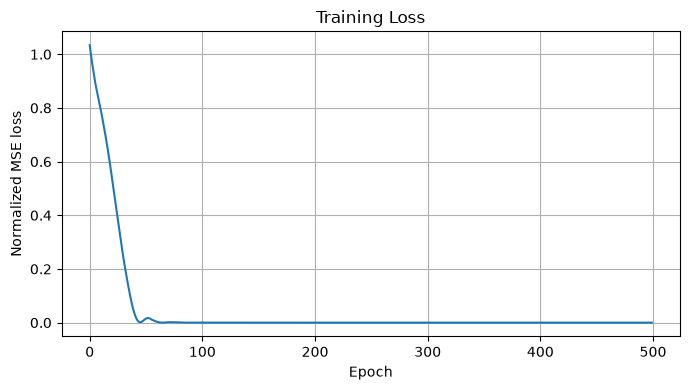

In [33]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Normalized MSE loss")
plt.title("Training Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

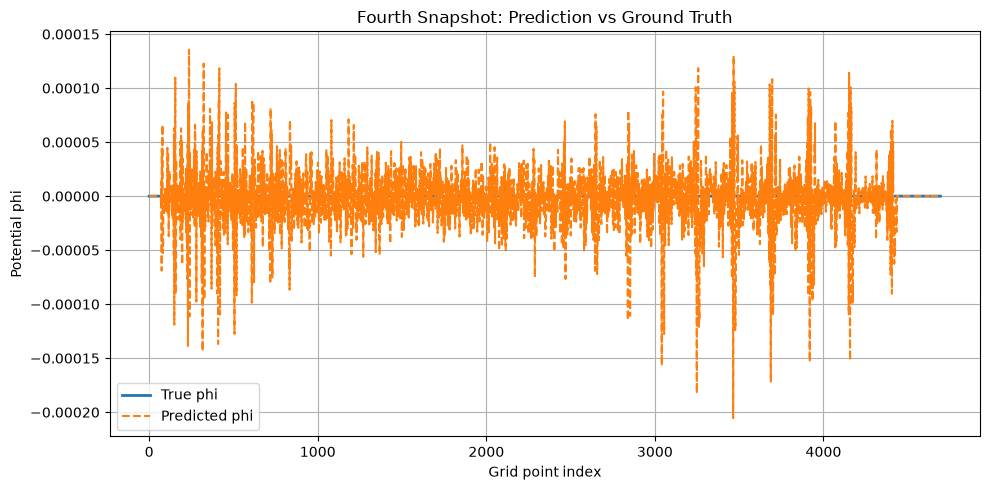

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(y_true, label="True phi", linewidth=2)
plt.plot(y_pred, "--", label="Predicted phi")

plt.xlabel("Grid point index")
plt.ylabel("Potential phi")
plt.title("Fourth Snapshot: Prediction vs Ground Truth")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

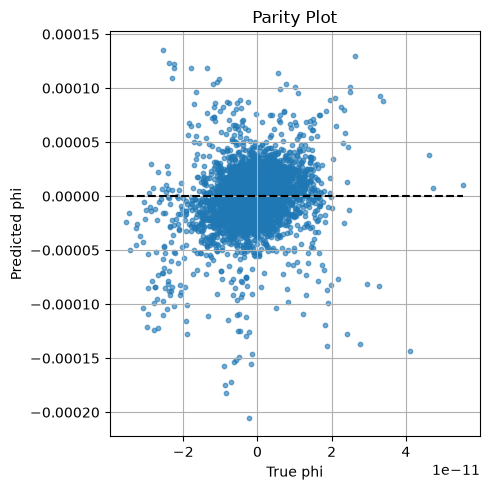

In [35]:
plt.figure(figsize=(5, 5))

plt.scatter(y_true, y_pred, s=10, alpha=0.6)

low = min(y_true.min(), y_pred.min())
high = max(y_true.max(), y_pred.max())

plt.plot([low, high], [low, high], "k--")

plt.xlabel("True phi")
plt.ylabel("Predicted phi")
plt.title("Parity Plot")
plt.grid(True)
plt.tight_layout()
plt.show()

Device: cpu
Epoch  300/3000 | Total: 3.5437e-03 | Data: 6.0537e-04 | Physics: 2.9383e-01
Epoch  600/3000 | Total: 1.6918e-03 | Data: 1.0764e-03 | Physics: 6.1543e-02
Epoch  900/3000 | Total: 1.3364e-03 | Data: 1.1079e-03 | Physics: 2.2851e-02
Epoch 1200/3000 | Total: 1.2949e-03 | Data: 1.1149e-03 | Physics: 1.7995e-02
Epoch 1500/3000 | Total: 1.2493e-03 | Data: 1.0634e-03 | Physics: 1.8597e-02
Epoch 1800/3000 | Total: 1.2374e-03 | Data: 1.0560e-03 | Physics: 1.8131e-02
Epoch 2100/3000 | Total: 1.2118e-03 | Data: 1.0110e-03 | Physics: 2.0073e-02
Epoch 2400/3000 | Total: 1.2016e-03 | Data: 1.0109e-03 | Physics: 1.9073e-02
Epoch 2700/3000 | Total: 1.1497e-03 | Data: 9.6370e-04 | Physics: 1.8602e-02
Epoch 3000/3000 | Total: 1.1703e-03 | Data: 9.6940e-04 | Physics: 2.0095e-02

Fourth snapshot test metrics
MSE = 4.632319e-03
MAE = 6.750570e-02
R²  = -83578056971439308800.000000


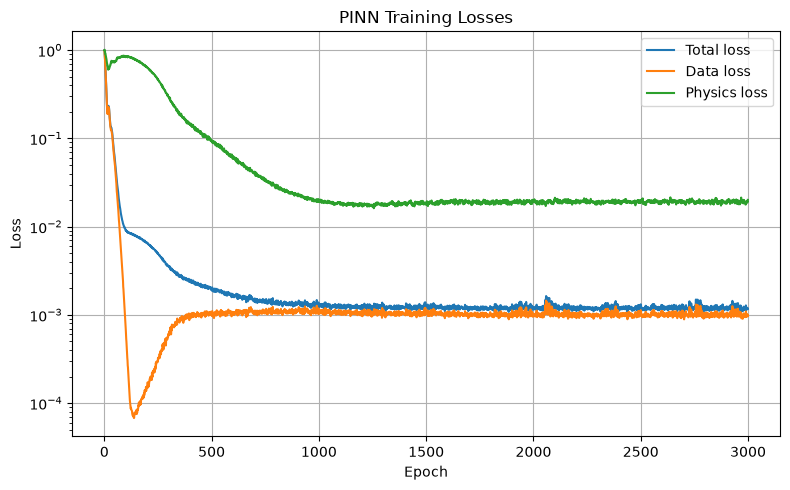

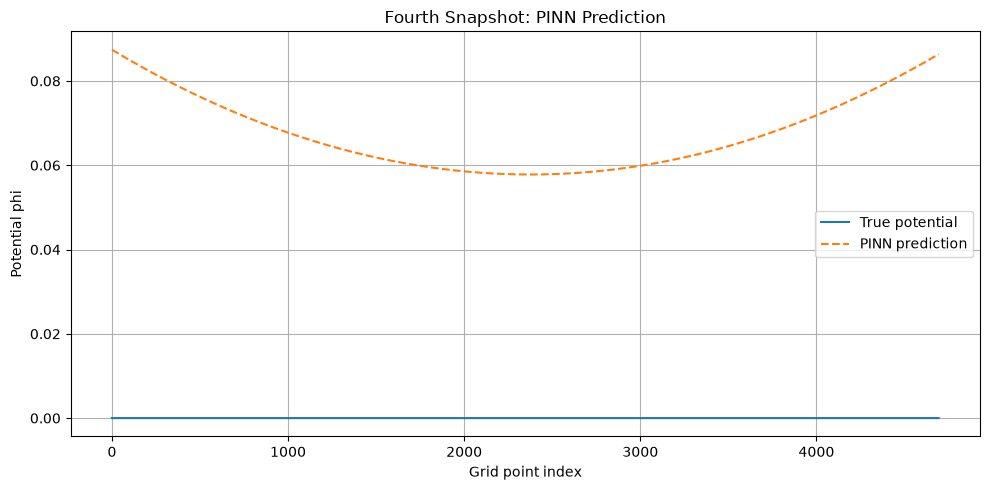

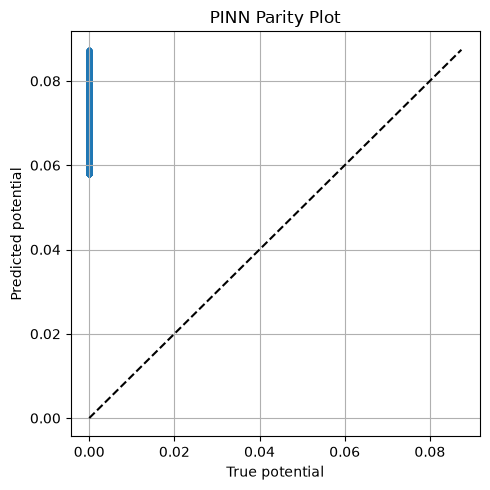

In [36]:
assert density.shape == phi.shape
assert density.shape[1] == 4

N, n_snapshots = density.shape


# ==================================================
# 2. Configure device and dimensionless coordinates
# ==================================================
torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)

# ASSUMPTION: uniformly spaced 1D grid.
# Replace with actual grid coordinates if available.
x_np = np.linspace(0.0, 1.0, N, dtype=np.float32)

# Snapshot labels are ordinal, not physical time.
# This avoids treating iteration 100 as a small time step.
# It does NOT establish that the dynamics are linear in time.
t_np = np.arange(n_snapshots, dtype=np.float32)

# ==================================================
# 3. Normalize using training snapshots only
# ==================================================
train_cols = [0, 1, 2]
test_col = 3

n_mean = density[:, train_cols].mean()
n_std = max(float(density[:, train_cols].std()), 1e-8)

p_mean = phi[:, train_cols].mean()
p_std = max(float(phi[:, train_cols].std()), 1e-8)

density_norm = (density - n_mean) / n_std
phi_norm = (phi - p_mean) / p_std

# Flatten spatial points across training snapshots.
X_train = np.concatenate([
    np.column_stack((
        x_np,
        np.full(N, t_np[j], dtype=np.float32)
    ))
    for j in train_cols
])

n_train = np.concatenate([
    density_norm[:, j] for j in train_cols
]).reshape(-1, 1)

y_train = np.concatenate([
    phi_norm[:, j] for j in train_cols
]).reshape(-1, 1)

# Fourth snapshot: held out from training.
X_test = np.column_stack((
    x_np,
    np.full(N, t_np[test_col], dtype=np.float32)
))

n_test = density_norm[:, test_col].reshape(-1, 1)
y_test = phi[:, test_col].reshape(-1, 1)

# Convert training arrays to device tensors.
X_train = torch.tensor(
    X_train, device=device, dtype=torch.float32
)
n_train = torch.tensor(
    n_train, device=device, dtype=torch.float32
)
y_train = torch.tensor(
    y_train, device=device, dtype=torch.float32
)

# ==================================================
# 4. Define PINN
# ==================================================
class PINN(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(2, 64),  # x, t
            nn.Tanh(),

            nn.Linear(64, 64),
            nn.Tanh(),

            nn.Linear(64, 64),
            nn.Tanh(),

            nn.Linear(64, 1)   # normalized phi
        )

    def forward(self, x, t):
        return self.net(torch.cat((x, t), dim=1))


model = PINN().to(device)

optimizer = torch.optim.Adam(
    model.parameters(), lr=1e-3
)

# ==================================================
# 5. Loss configuration
# ==================================================
# IMPORTANT:
# This is a dimensionless demonstration.
# lambda_poisson is NOT a physical constant.
lambda_poisson = 1.0

# Relative weight of the physics loss.
physics_weight = 0.01

epochs = 3000
batch_size = 2048

history_total = []
history_data = []
history_physics = []

# ==================================================
# 6. PINN training
# ==================================================
for epoch in range(epochs):
    model.train()

    # Random collocation/training points from
    # the first three snapshots.
    idx = torch.randint(
        0, X_train.shape[0],
        (min(batch_size, X_train.shape[0]),),
        device=device
    )

    xb = X_train[idx, 0:1].detach().clone()
    tb = X_train[idx, 1:2].detach()
    nb = n_train[idx]
    yb = y_train[idx]

    # Autograd needs x to calculate spatial derivatives.
    xb.requires_grad_(True)

    # Neural network prediction.
    phi_pred = model(xb, tb)

    # Supervised data loss.
    loss_data = torch.mean((phi_pred - yb) ** 2)

    # First derivative d(phi)/dx.
    dphi_dx = torch.autograd.grad(
        outputs=phi_pred,
        inputs=xb,
        grad_outputs=torch.ones_like(phi_pred),
        create_graph=True
    )[0]

    # Second derivative d²(phi)/dx².
    d2phi_dx2 = torch.autograd.grad(
        outputs=dphi_dx,
        inputs=xb,
        grad_outputs=torch.ones_like(dphi_dx),
        create_graph=True
    )[0]

    # Dimensionless, illustrative Poisson residual:
    # d²(phi)/dx² + lambda * normalized_source = 0
    residual = d2phi_dx2 + lambda_poisson * nb

    loss_physics = torch.mean(residual ** 2)

    # Combined PINN objective.
    loss = loss_data + physics_weight * loss_physics

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    history_total.append(loss.item())
    history_data.append(loss_data.item())
    history_physics.append(loss_physics.item())

    if (epoch + 1) % 300 == 0:
        print(
            f"Epoch {epoch+1:4d}/{epochs} | "
            f"Total: {loss.item():.4e} | "
            f"Data: {loss_data.item():.4e} | "
            f"Physics: {loss_physics.item():.4e}"
        )

# ==================================================
# 7. Test on the fourth snapshot
# ==================================================
model.eval()

xt = torch.tensor(
    X_test[:, 0:1],
    device=device,
    dtype=torch.float32
)
tt = torch.tensor(
    X_test[:, 1:2],
    device=device,
    dtype=torch.float32
)

with torch.no_grad():
    pred_norm = model(xt, tt)

    # Return to the original potential scale.
    pred_phi = pred_norm.cpu().numpy() * p_std + p_mean

true_phi = y_test.ravel()
pred_phi = pred_phi.ravel()

mse = np.mean((true_phi - pred_phi) ** 2)
mae = np.mean(np.abs(true_phi - pred_phi))

ss_tot = np.sum((true_phi - true_phi.mean()) ** 2)
ss_res = np.sum((true_phi - pred_phi) ** 2)
r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

print("\nFourth snapshot test metrics")
print(f"MSE = {mse:.6e}")
print(f"MAE = {mae:.6e}")
print(f"R²  = {r2:.6f}")

# ==================================================
# 8. Plot losses
# ==================================================
plt.figure(figsize=(8, 5))
plt.semilogy(history_total, label="Total loss")
plt.semilogy(history_data, label="Data loss")
plt.semilogy(history_physics, label="Physics loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PINN Training Losses")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ==================================================
# 9. Plot prediction on snapshot four
# ==================================================
plt.figure(figsize=(10, 5))
plt.plot(true_phi, label="True potential")
plt.plot(pred_phi, "--", label="PINN prediction")
plt.xlabel("Grid point index")
plt.ylabel("Potential phi")
plt.title("Fourth Snapshot: PINN Prediction")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ==================================================
# 10. Parity plot
# ==================================================
plt.figure(figsize=(5, 5))
plt.scatter(true_phi, pred_phi, s=10, alpha=0.6)

lo = min(true_phi.min(), pred_phi.min())
hi = max(true_phi.max(), pred_phi.max())
plt.plot([lo, hi], [lo, hi], "k--")

plt.xlabel("True potential")
plt.ylabel("Predicted potential")
plt.title("PINN Parity Plot")
plt.grid(True)
plt.tight_layout()
plt.show()
